# TP5 — Optimiser (1/2) : surapprentissage et régularisation
**ÉNONCÉ** · Durée estimée : **une demi-journée**

## 🎯 Ce que vous allez apprendre
- **Provoquer** puis reconnaître le surapprentissage sur des courbes
- Appliquer quatre remèdes : **arrêt précoce, dropout, L2, réseau plus petit**
- Mesurer le **bruit** pour savoir si une amélioration est **réelle**
- Fabriquer de nouvelles données : l'**augmentation de données**

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`EarlyStopping`  ·  `layers.Dropout`  ·  `regularizers.l2`  ·  `kernel_regularizer`  ·  `np.std`  ·  `np.sqrt`  ·  `np.roll`  ·  `np.concatenate`  ·  `set_random_seed`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [19]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
import keras
from keras import layers, regularizers
keras.utils.set_random_seed(42)

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

## Étape 1 — Préparer : un petit jeu pour provoquer le surapprentissage
On reprend les chiffres, mais on n'utilise que **300 images** pour apprendre. Avec peu de données et un gros réseau, la mémorisation est facile. Deux petites fonctions utilitaires sont fournies.

In [2]:
from sklearn.datasets import load_digits
chiffres = load_digits()
X = chiffres.data / 16.0
y = chiffres.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
petit_X, petit_y = X_train[:300], y_train[:300]

def courbes(histoire):
    h = histoire.history
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    ax[0].plot(h["loss"], label="apprentissage"); ax[0].plot(h["val_loss"], label="validation"); ax[0].set_title("Perte"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["accuracy"], label="apprentissage"); ax[1].plot(h["val_accuracy"], label="validation"); ax[1].set_title("Précision"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

def precision_test(modele, entrees=None):
    entrees = X_test if entrees is None else entrees
    return float(np.mean(np.argmax(modele.predict(entrees, verbose=0), axis=1) == y_test))

print(petit_X.shape, "images pour apprendre |", X_test.shape[0], "pour le test")

(300, 64) images pour apprendre | 450 pour le test


## 🎯 Étape 2 — Une fonction pour construire des réseaux variés
Pour comparer plusieurs réglages, on écrit **une fonction** qui construit le réseau à la demande. Le **dropout** éteint au hasard une proportion de neurones à chaque pas d'apprentissage, pour que le réseau ne s'appuie pas sur un seul neurone. La **régularisation L2** ajoute une pénalité sur les gros poids.

**À faire :** Écrivez `construire(neurones=256, dropout=0.0, l2=0.0, seed=42)` qui fixe la graine puis renvoie un modèle **compilé** : entrée 64, **deux couches Dense de `neurones` (ReLU)**, chacune suivie d'un `Dropout(dropout)`, avec `kernel_regularizer=regularizers.l2(l2)` si `l2 > 0`, puis une sortie **Dense 10 softmax**. Optimiseur adam, perte sparse_categorical_crossentropy, métrique accuracy.

> 💡 **Indice** : `layers.Dropout(0.0)` ne fait rien : pas besoin de le traiter à part. `regularizers.l2(valeur)`.

In [3]:
def construire(neurones=256, dropout=0.0, l2=0.0, seed=42):
    keras.utils.set_random_seed(seed)
    reg = regularizers.l2(l2) if l2 > 0 else None
    m = keras.Sequential([
        layers.Input(shape=(64,)),
        layers.Dense(neurones, activation="relu", kernel_regularizer=reg),
        layers.Dropout(dropout),
        layers.Dense(neurones, activation="relu", kernel_regularizer=reg),
        layers.Dropout(dropout),
        layers.Dense(10, activation="softmax"),
    ])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

In [4]:
# ✅ Contrôle (ne pas modifier)
controle(construire().count_params() == 85002 and construire(neurones=16).count_params() == 1482, 'Fonction correcte', 'Attendu 85 002 paramètres par défaut et 1 482 avec 16 neurones')

✅ Fonction correcte


## 🎯 Étape 3 — Provoquer le surapprentissage
Un réseau de 256 + 256 neurones (85 000 paramètres) pour apprendre sur **300 images** : il a largement de quoi **tout mémoriser**.

**À faire :** Créez `gros = construire()`. Entraînez-le sur `petit_X`, `petit_y` : **150 epochs**, batch de 32, **20 % de validation**, sans affichage → `histoire_gros`. Affichez les courbes avec `courbes(histoire_gros)` et calculez `acc_gros` (précision test avec `precision_test`).

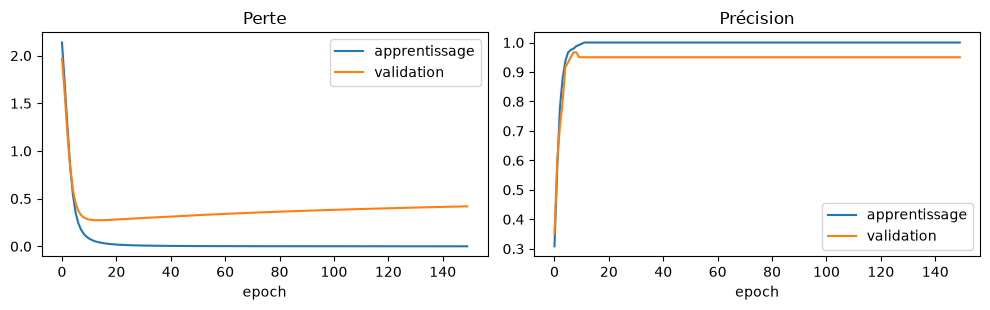

Précision test du gros réseau : 0.909


In [5]:
gros = construire()
histoire_gros = gros.fit(
    petit_X, petit_y,
    epochs=150, batch_size=32, validation_split=0.2, verbose=0,
)
courbes(histoire_gros)
acc_gros = precision_test(gros)
print(f"Précision test du gros réseau : {acc_gros:.3f}")

In [6]:
# ✅ Contrôle (ne pas modifier)
h = histoire_gros.history
controle(h['accuracy'][-1] > 0.99 and h['val_loss'][-1] > min(h['val_loss']), 'Surapprentissage provoqué : la perte de validation a remonté', 'Attendu : précision d\'apprentissage > 0.99 et perte de validation finale > son minimum')

✅ Surapprentissage provoqué : la perte de validation a remonté


### ✍️ Question
**Décrivez ce que vous voyez sur la courbe de perte. À partir de quand le réseau surapprend-il ? La précision de validation baisse-t-elle autant que la perte de validation remonte ?**

*Réponse:*
> *Réponse rédigée avec vos résultats dans la cellule de code ci-dessous (exécutez-la).*

In [7]:
# ✍️ Réponse rédigée à partir de vos résultats
from IPython.display import Markdown, display

h = histoire_gros.history
ep = int(np.argmin(h["val_loss"])) + 1
hausse = h["val_loss"][-1] / min(h["val_loss"]) - 1
baisse = (max(h["val_accuracy"]) - h["val_accuracy"][-1]) / max(h["val_accuracy"])
display(Markdown(
    f"> La perte d'apprentissage descend jusqu'à {h['loss'][-1]:.3f}, alors que la perte de validation atteint son minimum ({min(h['val_loss']):.2f}) vers l'epoch {ep} puis remonte jusqu'à {h['val_loss'][-1]:.2f} : le réseau surapprend à partir de cet epoch. "
    f"La précision de validation baisse {'beaucoup moins' if baisse < hausse else 'autant'} que la perte ne remonte (de {max(h['val_accuracy']):.3f} à {h['val_accuracy'][-1]:.3f}) : "
    "le réseau se trompe avec de plus en plus de confiance, sans forcément changer de réponse."
))

> La perte d'apprentissage descend jusqu'à 0.000, alors que la perte de validation atteint son minimum (0.27) vers l'epoch 15 puis remonte jusqu'à 0.42 : le réseau surapprend à partir de cet epoch. La précision de validation baisse beaucoup moins que la perte ne remonte (de 0.967 à 0.950) : le réseau se trompe avec de plus en plus de confiance, sans forcément changer de réponse.

## 🎯 Étape 4 — Comparer les remèdes
Même petit jeu, mêmes données, **cinq façons** de limiter le surapprentissage :
1. réseau de base, sans remède (référence) ;
2. **arrêt précoce** (patience 10, `restore_best_weights=True`) ;
3. **dropout 0,3** ;
4. **L2 = 1e-3** ;
5. **réseau plus petit** (16 neurones).

**À faire :** Pour chacune, entraînez avec `construire` (150 epochs max, batch 32, 20 % de validation) et rangez dans un tableau pandas **`resultats`** : `configuration`, `perte validation min`, `perte validation finale`, `epochs` effectués, `précision test`.

> 💡 **Indice** : Une boucle sur un dictionnaire de configurations. L'arrêt précoce se passe via `callbacks=[...]` dans `fit`. `len(histoire.history['loss'])` donne les epochs effectués.

In [8]:
remedes = {
    "base": {},
    "arrêt précoce": {},
    "dropout 0,3": {"dropout": 0.3},
    "L2 = 1e-3": {"l2": 1e-3},
    "réseau plus petit (16)": {"neurones": 16},
}

lignes = []
for nom, options in remedes.items():
    m = construire(**options)
    rappels = []
    if nom == "arrêt précoce":
        rappels = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)]
    h = m.fit(petit_X, petit_y, epochs=150, batch_size=32, validation_split=0.2,
              callbacks=rappels, verbose=0).history
    lignes.append({
        "configuration": nom,
        "perte validation min": min(h["val_loss"]),
        "perte validation finale": h["val_loss"][-1],
        "epochs": len(h["loss"]),
        "précision test": precision_test(m),
    })

resultats = pd.DataFrame(lignes)
resultats

,configuration,perte validation min,perte validation finale,epochs,précision test
0,base,0.273205,0.419099,150,0.908889
1,arrêt précoce,0.273205,0.287709,25,0.915556
2,"dropout 0,3",0.241841,0.337535,150,0.920000
3,L2 = 1e-3,0.317549,0.317549,150,0.911111
4,réseau plus petit (16),0.332749,0.334203,150,0.900000


In [9]:
# ✅ Contrôle (ne pas modifier)
controle(len(resultats) == 5 and (resultats['précision test'] > 0.8).all(), 'Tableau de 5 configurations', 'Attendu 5 lignes avec des précisions de test > 0.8')

✅ Tableau de 5 configurations


## Étape 5 — Combien de bruit ? Une différence de précision est-elle réelle ?
Avec 450 images de test, la précision d'un modèle est connue avec une **marge d'incertitude** : tester sur d'autres 450 images donnerait un résultat légèrement différent. Cette marge vaut environ `1,96 × √(p(1−p)/n)`. **Une différence plus petite que cette marge n'est pas une amélioration démontrée.**

In [10]:
p = resultats["précision test"].mean()
bruit = 1.96 * np.sqrt(p * (1 - p) / len(y_test))
print(f"Avec {len(y_test)} images de test, une différence inférieure à environ {bruit:.3f} est dans le bruit.")
print("Écart entre la meilleure et la moins bonne précision test du tableau :", round(resultats["précision test"].max() - resultats["précision test"].min(), 3))

Avec 450 images de test, une différence inférieure à environ 0.026 est dans le bruit.
Écart entre la meilleure et la moins bonne précision test du tableau : 0.02


### ✍️ Question
**Quel remède vous paraît le meilleur ? Les écarts de précision dépassent-ils le bruit ? Quelle autre colonne du tableau permet de mieux les distinguer ?**

*Réponse:*
> *Réponse rédigée avec vos résultats dans la cellule de code ci-dessous (exécutez-la).*

In [11]:
# ✍️ Réponse rédigée à partir de vos résultats
from IPython.display import Markdown, display

meilleur = resultats.loc[resultats["perte validation min"].idxmin(), "configuration"]
ecart = resultats["précision test"].max() - resultats["précision test"].min()
if ecart > bruit:
    phrase = "Les écarts de précision dépassent le bruit : au moins certains remèdes sont vraiment différents."
else:
    phrase = "Les écarts de précision ne dépassent pas le bruit : la précision seule ne permet pas de conclure."
display(Markdown(
    f"> Le remède avec la plus basse perte de validation est « {meilleur} ». "
    f"L'écart de précision test entre la meilleure et la moins bonne configuration est de {ecart:.3f}, pour un bruit d'environ {bruit:.3f}. {phrase} "
    "Les colonnes « perte validation » (minimum et finale) distinguent mieux les remèdes, car la perte réagit même quand la précision ne bouge pas."
))

> Le remède avec la plus basse perte de validation est « dropout 0,3 ». L'écart de précision test entre la meilleure et la moins bonne configuration est de 0.020, pour un bruit d'environ 0.026. Les écarts de précision ne dépassent pas le bruit : la précision seule ne permet pas de conclure. Les colonnes « perte validation » (minimum et finale) distinguent mieux les remèdes, car la perte réagit même quand la précision ne bouge pas.

## 🎯 Étape 6 — Mesurer la variabilité : un résultat dépend aussi de la graine
Le hasard intervient partout (poids de départ, ordre des données). Un même réglage donne donc des résultats légèrement différents d'une exécution à l'autre. **Avant de conclure qu'un réglage est meilleur, on le répète.**

**À faire :** Pour la configuration de **base** puis pour **`dropout=0.3`**, entraînez **5 modèles** avec les graines `0, 1, 2, 3, 4` (100 epochs, batch 32, sans validation). Rangez les précisions test dans deux listes `acc_base` et `acc_dropout`. Affichez moyenne ± écart-type de chacune.

> 💡 **Indice** : `construire(seed=s)` fixe la graine. `np.mean`, `np.std`.

In [12]:
acc_base, acc_dropout = [], []
for s in range(5):
    m = construire(seed=s)
    m.fit(petit_X, petit_y, epochs=100, batch_size=32, verbose=0)
    acc_base.append(precision_test(m))

    m = construire(dropout=0.3, seed=s)
    m.fit(petit_X, petit_y, epochs=100, batch_size=32, verbose=0)
    acc_dropout.append(precision_test(m))

print(f"base    : {np.mean(acc_base):.3f} ± {np.std(acc_base):.3f}")
print(f"dropout : {np.mean(acc_dropout):.3f} ± {np.std(acc_dropout):.3f}")

base    : 0.942 ± 0.006
dropout : 0.944 ± 0.001


In [13]:
# ✅ Contrôle (ne pas modifier)
controle(len(acc_base) == 5 and len(acc_dropout) == 5, 'Deux séries de 5 entraînements', 'Attendu 5 valeurs dans chaque liste')

✅ Deux séries de 5 entraînements


### ✍️ Question
**Un écart de 1 point de précision entre deux configurations suffit-il à conclure que l'une est meilleure ?**

*Réponse :*
> *Réponse rédigée avec vos résultats dans la cellule de code ci-dessous (exécutez-la).*

In [14]:
# ✍️ Réponse rédigée à partir de vos résultats
from IPython.display import Markdown, display

diff = np.mean(acc_dropout) - np.mean(acc_base)
display(Markdown(
    f"> Non, pas forcément. La précision varie d'une graine à l'autre (écart-type {np.std(acc_base):.3f} pour la base, {np.std(acc_dropout):.3f} avec dropout) "
    f"et le test de {len(y_test)} images a une marge d'environ ±{bruit:.3f}. "
    f"Un écart de 0,01 est du même ordre ou plus petit que ces variations : il faut répéter avec plusieurs graines et vérifier que l'écart des moyennes ({diff:+.3f} ici) les dépasse avant de conclure."
))

> Non, pas forcément. La précision varie d'une graine à l'autre (écart-type 0.006 pour la base, 0.001 avec dropout) et le test de 450 images a une marge d'environ ±0.026. Un écart de 0,01 est du même ordre ou plus petit que ces variations : il faut répéter avec plusieurs graines et vérifier que l'écart des moyennes (+0.001 ici) les dépasse avant de conclure.

## Étape 7 — Préparer l'augmentation de données : un CNN et des images décalées
Au TP4, un petit décalage trompait les modèles. L'**augmentation de données** fabrique des variantes des images d'apprentissage (ici, décalées) pour que le modèle apprenne que **la position ne compte pas**. On reprend le CNN du TP4.

In [15]:
I_train = X_train.reshape(-1, 8, 8, 1)
I_test = X_test.reshape(-1, 8, 8, 1)
I_test_decale = np.roll(I_test, 1, axis=2)

def cnn(seed=42):
    keras.utils.set_random_seed(seed)
    m = keras.Sequential([layers.Input(shape=(8, 8, 1)), layers.Conv2D(16, 3, padding="same", activation="relu"), layers.MaxPooling2D(2),
                          layers.Conv2D(32, 3, activation="relu"), layers.Flatten(), layers.Dense(10, activation="softmax")])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def precision_images(modele, images):
    return float(np.mean(np.argmax(modele.predict(images, verbose=0), axis=1) == y_test))
print(I_train.shape, I_test_decale.shape)

(1347, 8, 8, 1) (450, 8, 8, 1)


## 🎯 Étape 8 — Augmenter les données par décalage
⚠️ Deux règles : on n'augmente **que l'apprentissage, jamais le test** ; et on n'utilise pas ici de `validation_split` (il prendrait la fin du tableau, qui contiendrait des copies décalées d'images déjà vues).

**À faire :** Fabriquez `I_aug` et `y_aug` : les images d'apprentissage **plus leurs 4 versions décalées d'un pixel** (colonne +1, colonne −1, ligne +1, ligne −1). Entraînez `cnn_base` sur `I_train` et `cnn_aug` sur `I_aug` (**30 epochs**, batch 32, sans validation). Calculez les précisions sur `I_test` et `I_test_decale` dans un tableau `bilan`.

> 💡 **Indice** : `np.roll(I_train, 1, axis=2)` décale les colonnes ; `axis=1` les lignes. `np.concatenate([...])`. Les étiquettes `y_train` sont à répéter autant de fois.

In [16]:
# Données augmentées : originales + 4 versions décalées d'un pixel
I_aug = np.concatenate([
    I_train,
    np.roll(I_train, 1, axis=2),    # colonne +1
    np.roll(I_train, -1, axis=2),   # colonne -1
    np.roll(I_train, 1, axis=1),    # ligne +1
    np.roll(I_train, -1, axis=1),   # ligne -1
])
y_aug = np.tile(y_train, 5)

cnn_base = cnn()
cnn_base.fit(I_train, y_train, epochs=30, batch_size=32, verbose=0)
cnn_aug = cnn()
cnn_aug.fit(I_aug, y_aug, epochs=30, batch_size=32, verbose=0)

bilan = pd.DataFrame({
    "modèle": ["sans augmentation", "avec augmentation"],
    "images normales": [precision_images(cnn_base, I_test), precision_images(cnn_aug, I_test)],
    "images décalées": [precision_images(cnn_base, I_test_decale), precision_images(cnn_aug, I_test_decale)],
})
bilan

,modèle,images normales,images décalées
0,sans augmentation,0.973333,0.557778
1,avec augmentation,0.991111,0.973333


In [17]:
# ✅ Contrôle (ne pas modifier)
controle(len(I_aug) == 5 * len(I_train) and bilan.loc[1, 'images décalées'] > bilan.loc[0, 'images décalées'], "L'augmentation améliore nettement les images décalées", 'Attendu : 5 fois plus d\'images et une meilleure précision sur images décalées avec augmentation')

✅ L'augmentation améliore nettement les images décalées


### ✍️ Question
**Qu'a apporté l'augmentation ? Quelle est sa limite ?**

*Réponse :*
> *Réponse rédigée avec vos résultats dans la cellule de code ci-dessous (exécutez-la).*

In [18]:
# ✍️ Réponse rédigée à partir de vos résultats
from IPython.display import Markdown, display

n0, n1 = bilan.loc[0, "images normales"], bilan.loc[1, "images normales"]
d0, d1 = bilan.loc[0, "images décalées"], bilan.loc[1, "images décalées"]
perte = "sans perte notable" if n1 >= n0 - 0.01 else "avec une petite perte"
display(Markdown(
    f"> L'augmentation fait passer la précision sur images décalées de {d0:.3f} à {d1:.3f}, {perte} sur les images normales ({n0:.3f} → {n1:.3f}) : le modèle a appris que la position ne compte pas. "
    "Sa limite : il n'est robuste qu'aux variations qu'on a fabriquées (ici des décalages d'un pixel). "
    "Un décalage plus grand, une rotation ou un changement d'échelle restent un problème, et l'entraînement est 5 fois plus long."
))

> L'augmentation fait passer la précision sur images décalées de 0.558 à 0.973, sans perte notable sur les images normales (0.973 → 0.991) : le modèle a appris que la position ne compte pas. Sa limite : il n'est robuste qu'aux variations qu'on a fabriquées (ici des décalages d'un pixel). Un décalage plus grand, une rotation ou un changement d'échelle restent un problème, et l'entraînement est 5 fois plus long.

## ✅ Ce qu'il faut retenir
- **Surapprentissage** : la perte d'apprentissage baisse, celle de validation **remonte**. La **précision** peut rester stable pendant ce temps, d'où l'intérêt de regarder la **perte**.
- Remèdes : **arrêt précoce, dropout, L2, réseau plus petit, plus de données** (ou augmentation).
- **Un gain n'existe que s'il dépasse le bruit** : bruit d'échantillonnage (taille du test) et variabilité entre graines.
- **L'augmentation de données** apprend au modèle ce qu'il doit ignorer. On n'augmente jamais le test.